🚀 TEST DU MODULE E6 - SCORING QUALITÉ
✅ Dataset créé : 100 lignes
🎯 CALCUL DES SCORES DE QUALITÉ : CONTRACT

📊 Calcul du score de COMPLÉTUDE pour CONTRACT...
   ✅ Score de complétude : 99.80%

📊 Calcul du score de VALIDITÉ pour CONTRACT...
   ✅ Score de validité : 99.00%

📊 Calcul du score de COHÉRENCE pour CONTRACT...
   ✅ Score de cohérence : 99.00%

📊 Calcul du score d'UNICITÉ pour CONTRACT...
   ✅ Score d'unicité : 100.00%

📊 Calcul du score d'INTÉGRITÉ RÉFÉRENTIELLE pour CONTRACT...
   ✅ Score d'intégrité référentielle : 100.00%

📊 Calcul du SCORE GLOBAL pondéré...
   ✅ Score global : 99.56%

📊 RAPPORT DE SCORING QUALITÉ
   📅 Date : 2026-10-13T21:45:00.009693
   🎯 Score global : 99.56%
      ✅ EXCELLENT - Données de très haute qualité

   📋 Scores par table :

      📊 CONTRACT :
         ✅ COMPLETUDE : 99.80%
         ✅ VALIDITE : 99.00%
         ✅ COHERENCE : 99.00%
         ✅ UNICITE : 100.00%
         ✅ INTEGRITE_REFERENTIELLE : 100.00%

📊 GÉNÉRATION DES VISUALISATIONS
   💾 Gra

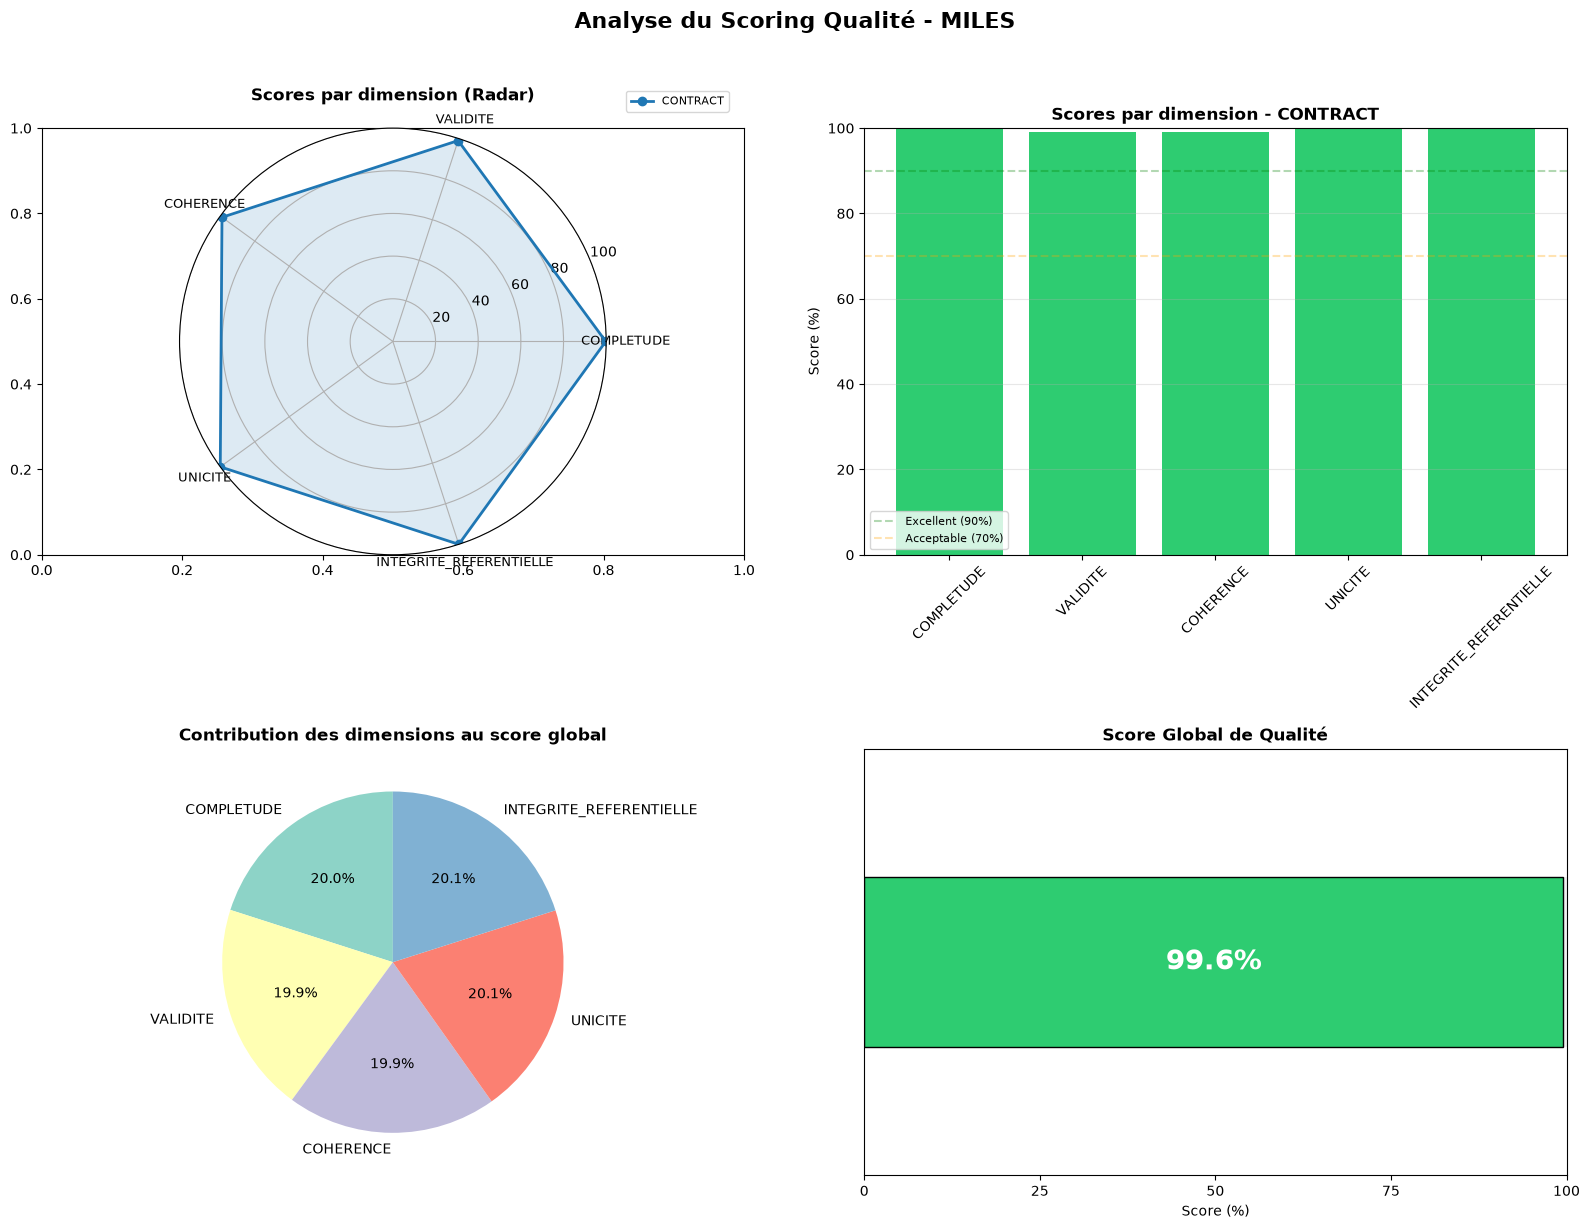

   💾 Rapport JSON exporté : ..\docs\rapport_scoring.json
   💾 Rapport Excel exporté : ..\docs\rapport_scoring.xlsx

🏁 FIN - Module E6 testé avec succès !


In [1]:
# Cellule : Test du module E6 - Scoring

import sys
sys.path.append('.')

import importlib
import scoring
importlib.reload(scoring)

from scoring import ScoringEngine
import pandas as pd
import numpy as np

print("=" * 60)
print("🚀 TEST DU MODULE E6 - SCORING QUALITÉ")
print("=" * 60)

# 1. Créer des données de test
np.random.seed(42)
n = 100

df_contract = pd.DataFrame({
    "CONTRACT_ID": range(1, n+1),
    "REFERENCE": [f"REF{i:03d}" for i in range(1, n+1)],
    "START_DATE": pd.date_range('2024-01-01', periods=n),
    "END_DATE": pd.date_range('2025-01-01', periods=n),
    "AMOUNT": np.random.normal(20000, 5000, n).round(2),
})

# Ajouter des anomalies
df_contract.loc[5, 'REFERENCE'] = None
df_contract.loc[10, 'AMOUNT'] = -5000
df_contract.loc[15, 'END_DATE'] = pd.Timestamp('2023-01-01')

print(f"✅ Dataset créé : {len(df_contract)} lignes")

# 2. Initialiser le moteur
engine = ScoringEngine()

# 3. Calculer tous les scores
resultats = engine.calculer_tous_les_scores(
    df_contract,
    "CONTRACT",
    colonnes_obligatoires=["CONTRACT_ID", "REFERENCE", "START_DATE", "END_DATE", "AMOUNT"],
    contraintes=[
        {"colonne": "AMOUNT", "type": "POSITIVE"},
        {"colonne": "REFERENCE", "type": "NOT_NULL"}
    ],
    regles=[
        {"nom": "DATE_RANGE", "condition": lambda d: (d['END_DATE'].isna()) | (d['END_DATE'] >= d['START_DATE'])}
    ],
    cles_uniques=["CONTRACT_ID"]
)

# 4. Afficher le rapport
engine.afficher_rapport()

# 5. Visualiser
engine.visualiser_scores()

# 6. Exporter
engine.exporter_rapport_json()
engine.exporter_rapport_excel()

print("\n" + "=" * 60)
print("🏁 FIN - Module E6 testé avec succès !")
print("=" * 60)